# CC3092 – Deep Learning · Laboratorio 8
**Mini-GPT con muestreo controlado + embeddings contextuales (BERT) vs. estáticos (Word2Vec)**

Todo el Mini-GPT está construido *from scratch* con tensores y `nn.Parameter`/proyecciones lineales:
- Sin `nn.MultiheadAttention`, `nn.Transformer`, `nn.LayerNorm`.
- LayerNorm, softmax, cross-entropy, Positional Encoding (seno/coseno), atención multi-cabeza, PCA y similitud coseno programados a mano.
- Minibatches generados manualmente (índices), sin `DataLoader`.
- Learning rate con decaimiento expuesto en el bucle de entrenamiento + `clip_grad_norm_`.

Dependencias: `pip install torch numpy matplotlib pandas transformers gensim`

In [4]:
import os, math, time, re, itertools, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 1337
torch.manual_seed(SEED)
np.random.seed(SEED)
print("device:", device)

device: cpu


## Task 1.1 – Dataset, vocabulario y batches

In [5]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
DATA_PATH = "input.txt"
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(URL, DATA_PATH)
with open(DATA_PATH, "r", encoding="utf-8") as f:
    text = f.read()
print("Caracteres totales:", len(text))

# Vocabulario de caracteres únicos y mappings bidireccionales char <-> índice
chars = sorted(set(text))
vocab_size = len(chars)
assert vocab_size == 65, f"Se esperaban 65 caracteres, hay {vocab_size}"
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

def encode(s):
    return [stoi[c] for c in s]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

# Texto completo como secuencia de índices + split temporal 90/10 (sin barajar)
data = torch.tensor(encode(text), dtype=torch.long)
n_split = int(0.9 * len(data))
train_data, val_data = data[:n_split], data[n_split:]
print("train:", len(train_data), "| val:", len(val_data), "| vocab:", vocab_size)

# ---------------- Hiperparámetros ----------------
block_size = 128
d_model    = 128
n_heads    = 4
n_layers   = 3
batch_size = 64
lr         = 3e-4
epochs     = 10
# Extras (no contradicen el enunciado)
dropout      = 0.1
d_ff         = 4 * d_model
grad_clip    = 1.0      # clip_grad_norm_ contra explosión de gradientes
warmup_steps = 100
lr_min       = 3e-5
STRIDE       = 64       # paso de la ventana deslizante en entrenamiento (menor = más pasos por época)

Caracteres totales: 1115394
train: 1003854 | val: 111540 | vocab: 65


In [6]:
# ---------------- Generación manual de batches (ventanas deslizantes por índices) ----------------
def make_window_starts(n_tokens, block_size, stride):
    # Un inicio s es válido si s + block_size + 1 <= n_tokens (necesitamos el target desplazado +1)
    last_start = n_tokens - block_size - 1
    return torch.arange(0, last_start + 1, stride)

def build_batch(split_data, starts, block_size):
    # idx[b, t] = starts[b] + t  ->  x = data[idx],  y = data[idx + 1]  (target = input desplazado 1 paso)
    offs = torch.arange(block_size)
    idx = starts[:, None] + offs[None, :]
    x = split_data[idx]
    y = split_data[idx + 1]
    return x.to(device), y.to(device)

def epoch_batches(split_data, block_size, batch_size, stride, shuffle=True, drop_last=True):
    starts = make_window_starts(len(split_data), block_size, stride)
    if shuffle:
        starts = starts[torch.randperm(len(starts))]    # permutación de índices
    n = len(starts)
    end = (n // batch_size) * batch_size if drop_last else n
    for i in range(0, end, batch_size):
        yield build_batch(split_data, starts[i:i + batch_size], block_size)

# Sanity check: y es x desplazado un paso
xb, yb = next(epoch_batches(train_data, block_size, batch_size, STRIDE))
assert torch.equal(xb[:, 1:], yb[:, :-1])
print("batch:", xb.shape, yb.shape)
print("x[0][:30] ->", repr(decode(xb[0, :30].cpu())))
print("y[0][:30] ->", repr(decode(yb[0, :30].cpu())))

batch: torch.Size([64, 128]) torch.Size([64, 128])
x[0][:30] -> 'e,\nA thirsty evil; and when we'
y[0][:30] -> ',\nA thirsty evil; and when we '


### Mini-GPT desde cero
Bloques: Positional Encoding sinusoidal, LayerNorm manual (varianza sesgada), atención causal multi-cabeza explícita, FFN con GELU, arquitectura Pre-LN.

In [7]:
# ---------------- Softmax estable (manual) ----------------
def softmax(z, dim=-1):
    # softmax(z)_i = exp(z_i - max z) / sum_j exp(z_j - max z)
    z = z - z.max(dim=dim, keepdim=True).values
    e = torch.exp(z)
    return e / e.sum(dim=dim, keepdim=True)

# ---------------- Cross-entropy manual ----------------
def cross_entropy(logits, targets, reduction="mean"):
    # L_t = -log softmax(z)_{y_t} = logsumexp(z) - z_{y_t}
    V = logits.size(-1)
    logits = logits.reshape(-1, V)
    t = targets.reshape(-1)
    m = logits.max(dim=-1, keepdim=True).values
    lse = m.squeeze(-1) + torch.log(torch.exp(logits - m).sum(dim=-1))
    nll = lse - logits.gather(1, t[:, None]).squeeze(1)
    return nll.sum() if reduction == "sum" else nll.mean()

# ---------------- LayerNorm manual ----------------
class LayerNormManual(nn.Module):
    def __init__(self, d, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.gamma = nn.Parameter(torch.ones(d))
        self.beta = nn.Parameter(torch.zeros(d))
    def forward(self, x):
        mu = x.mean(dim=-1, keepdim=True)                       # mu = (1/d) sum x_i
        var = ((x - mu) ** 2).mean(dim=-1, keepdim=True)        # sigma^2 sesgada = (1/d) sum (x_i - mu)^2
        x_hat = (x - mu) / torch.sqrt(var + self.eps)           # x_hat = (x - mu) / sqrt(sigma^2 + eps)
        return self.gamma * x_hat + self.beta                   # y = gamma * x_hat + beta

# ---------------- Positional Encoding sinusoidal ----------------
def sinusoidal_positional_encoding(max_len, d_model):
    # PE(pos, 2i)   = sin(pos / 10000^(2i/d_model))
    # PE(pos, 2i+1) = cos(pos / 10000^(2i/d_model))
    pos = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)          # (T,1)
    two_i = torch.arange(0, d_model, 2, dtype=torch.float32)               # 2i
    div = torch.exp(-math.log(10000.0) * two_i / d_model)                  # 1 / 10000^(2i/d)
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)
    return pe

# ---------------- Atención causal multi-cabeza ----------------
class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads, block_size, dropout):
        super().__init__()
        assert d_model % n_heads == 0
        self.h = n_heads
        self.dk = d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model, bias=False)
        self.W_k = nn.Linear(d_model, d_model, bias=False)
        self.W_v = nn.Linear(d_model, d_model, bias=False)
        self.W_o = nn.Linear(d_model, d_model)
        self.p = dropout
        self.register_buffer("causal", torch.tril(torch.ones(block_size, block_size, dtype=torch.bool)))
    def forward(self, x):
        B, T, C = x.shape
        # Q = X W_q, K = X W_k, V = X W_v  -> separar en cabezas (B, h, T, dk)
        q = self.W_q(x).view(B, T, self.h, self.dk).transpose(1, 2)
        k = self.W_k(x).view(B, T, self.h, self.dk).transpose(1, 2)
        v = self.W_v(x).view(B, T, self.h, self.dk).transpose(1, 2)
        # scores = Q K^T / sqrt(d_k)
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.dk)
        # máscara causal: posición t no atiende a j > t
        scores = scores.masked_fill(~self.causal[:T, :T], float("-inf"))
        A = softmax(scores, dim=-1)                       # A = softmax(QK^T / sqrt(dk))
        A = F.dropout(A, p=self.p, training=self.training)
        heads = A @ v                                      # head_i = A_i V_i
        concat = heads.transpose(1, 2).contiguous().view(B, T, C)   # Concat(head_1..head_h)
        return self.W_o(concat)                            # MHA = Concat(...) W_o

class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout):
        super().__init__()
        self.W1 = nn.Linear(d_model, d_ff)
        self.W2 = nn.Linear(d_ff, d_model)
        self.p = dropout
    def forward(self, x):
        # FFN(x) = W2 GELU(W1 x + b1) + b2
        return F.dropout(self.W2(F.gelu(self.W1(x))), p=self.p, training=self.training)

class Block(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, block_size, dropout):
        super().__init__()
        self.ln1 = LayerNormManual(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads, block_size, dropout)
        self.ln2 = LayerNormManual(d_model)
        self.ffn = FeedForward(d_model, d_ff, dropout)
        self.p = dropout
    def forward(self, x):
        x = x + F.dropout(self.attn(self.ln1(x)), p=self.p, training=self.training)   # x + MHA(LN(x))
        x = x + self.ffn(self.ln2(x))                                                  # x + FFN(LN(x))
        return x

class MiniGPT(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_layers, d_ff, block_size, dropout):
        super().__init__()
        self.d_model = d_model
        self.block_size = block_size
        self.p = dropout
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.register_buffer("pe", sinusoidal_positional_encoding(block_size, d_model))
        self.blocks = nn.ModuleList([Block(d_model, n_heads, d_ff, block_size, dropout) for _ in range(n_layers)])
        self.ln_f = LayerNormManual(d_model)
        self.head = nn.Linear(d_model, vocab_size)
        self.apply(self._init)
    def _init(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)
    def forward(self, idx):
        B, T = idx.shape
        x = self.tok_emb(idx) * math.sqrt(self.d_model) + self.pe[:T]   # emb * sqrt(d) + PE
        x = F.dropout(x, p=self.p, training=self.training)
        for blk in self.blocks:
            x = blk(x)
        return self.head(self.ln_f(x))                                   # logits (B, T, V)

model = MiniGPT(vocab_size, d_model, n_heads, n_layers, d_ff, block_size, dropout).to(device)
print("Parámetros:", sum(p.numel() for p in model.parameters()))

Parámetros: 610625


## Task 1.2 – Entrenamiento, curvas y perplejidad

In [8]:
@torch.no_grad()
def evaluate(model, split_data, eval_batch=128):
    # Evalúa sobre ventanas NO solapadas (stride = block_size) y promedia la CE por token
    model.eval()
    total_nll, total_tokens = 0.0, 0
    for xb, yb in epoch_batches(split_data, block_size, eval_batch, stride=block_size, shuffle=False, drop_last=False):
        logits = model(xb)
        total_nll += cross_entropy(logits, yb, reduction="sum").item()
        total_tokens += yb.numel()
    return total_nll / total_tokens        # (1/N) sum L_t

def lr_at_step(step, total_steps):
    # warmup lineal y luego decaimiento coseno: lr_t = lr_min + 0.5 (lr - lr_min)(1 + cos(pi * progreso))
    if step < warmup_steps:
        return lr * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return lr_min + 0.5 * (lr - lr_min) * (1 + math.cos(math.pi * progress))

optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
steps_per_epoch = len(make_window_starts(len(train_data), block_size, STRIDE)) // batch_size
total_steps = steps_per_epoch * epochs
print("steps/época:", steps_per_epoch, "| pasos totales:", total_steps)

train_losses, val_losses = [], []
step = 0
t0 = time.time()
for epoch in range(1, epochs + 1):
    model.train()
    running, count = 0.0, 0
    for xb, yb in epoch_batches(train_data, block_size, batch_size, STRIDE, shuffle=True):
        cur_lr = lr_at_step(step, total_steps)
        for g in optimizer.param_groups:
            g["lr"] = cur_lr
        logits = model(xb)
        loss = cross_entropy(logits, yb)                       # L = (1/N) sum -log p(y_t | x_<=t)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()
        running += loss.item(); count += 1; step += 1
    tr = running / count
    va = evaluate(model, val_data)
    train_losses.append(tr); val_losses.append(va)
    print(f"Época {epoch:2d}/{epochs} | train {tr:.4f} | val {va:.4f} | ppl val {math.exp(va):.3f} | lr {cur_lr:.2e} | {time.time()-t0:.0f}s")

torch.save(model.state_dict(), "mini_gpt_shakespeare.pt")

steps/época: 245 | pasos totales: 2450
Época  1/10 | train 3.0745 | val 2.4674 | ppl val 11.791 | lr 2.98e-04 | 149s
Época  2/10 | train 2.3972 | val 2.2800 | ppl val 9.776 | lr 2.82e-04 | 303s
Época  3/10 | train 2.2573 | val 2.1662 | ppl val 8.725 | lr 2.54e-04 | 535s
Época  4/10 | train 2.1499 | val 2.0797 | ppl val 8.002 | lr 2.17e-04 | 727s
Época  5/10 | train 2.0670 | val 2.0218 | ppl val 7.552 | lr 1.74e-04 | 920s
Época  6/10 | train 2.0075 | val 1.9840 | ppl val 7.272 | lr 1.30e-04 | 1094s
Época  7/10 | train 1.9650 | val 1.9567 | ppl val 7.076 | lr 9.02e-05 | 1266s
Época  8/10 | train 1.9367 | val 1.9418 | ppl val 6.971 | lr 5.81e-05 | 1426s
Época  9/10 | train 1.9189 | val 1.9320 | ppl val 6.903 | lr 3.72e-05 | 1583s
Época 10/10 | train 1.9083 | val 1.9291 | ppl val 6.883 | lr 3.00e-05 | 1745s


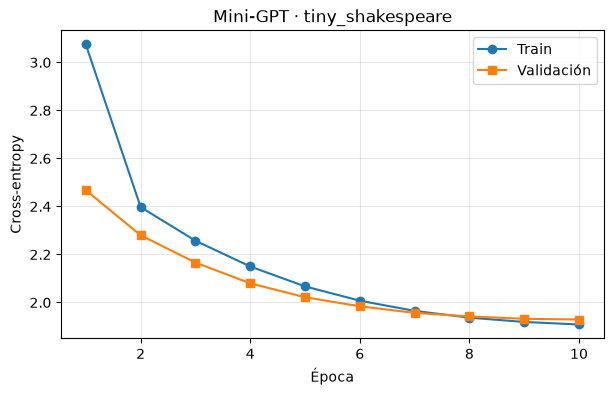

Pérdida de validación: 1.9291
Perplejidad de validación: 6.883  (rango esperado: 3.5 – 8.0)


In [9]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), train_losses, marker="o", label="Train")
plt.plot(range(1, epochs + 1), val_losses, marker="s", label="Validación")
plt.xlabel("Época"); plt.ylabel("Cross-entropy"); plt.title("Mini-GPT · tiny_shakespeare")
plt.grid(alpha=0.3); plt.legend(); plt.show()

# Perplejidad = exp( (1/N) * sum_t L_t )
val_loss = evaluate(model, val_data)
val_ppl = math.exp(val_loss)
print(f"Pérdida de validación: {val_loss:.4f}")
print(f"Perplejidad de validación: {val_ppl:.3f}  (rango esperado: 3.5 – 8.0)")

## Task 1.3 – Funciones de muestreo (desde cero)
Reciben logits crudos de forma `(vocab_size,)` y retornan el índice del siguiente token.

In [10]:
def sample_greedy(logits):
    # i* = argmax_i z_i
    return int(torch.argmax(logits))

def sample_top_k(logits, k, tau):
    z = logits / tau                                   # z_i / tau
    k = min(k, z.numel())
    sorted_z, _ = torch.sort(z, descending=True)
    kth = sorted_z[k - 1]                              # k-ésimo mayor valor
    z = z.masked_fill(z < kth, float("-inf"))          # los demás -> -inf
    probs = softmax(z)                                 # P(w_i|ctx) = exp(z_i/tau) / sum_j exp(z_j/tau)
    return int(torch.multinomial(probs, 1))

def sample_top_p(logits, p, tau):
    probs = softmax(logits / tau)                      # softmax con temperatura
    sorted_p, sorted_idx = torch.sort(probs, descending=True)
    cum = torch.cumsum(sorted_p, dim=0)
    # Se incluyen tokens hasta que la prob. acumulada supera p (el que cruza el umbral también entra):
    keep = (cum - sorted_p) < p
    nucleus = sorted_p * keep
    nucleus = nucleus / nucleus.sum()                  # renormalizar
    j = torch.multinomial(nucleus, 1)
    return int(sorted_idx[j])

# Tests rápidos
_t = torch.tensor([2.0, 1.0, 0.5, -1.0, 3.0])
print("greedy:", sample_greedy(_t), "(esperado 4)")
print("top-k k=1:", sample_top_k(_t, 1, 1.0), "(esperado 4)")
print("top-p p=0.01:", sample_top_p(_t, 0.01, 1.0), "(esperado 4)")

greedy: 4 (esperado 4)
top-k k=1: 4 (esperado 4)
top-p p=0.01: 4 (esperado 4)


## Task 2.1 – `generate` y muestras por configuración

In [11]:
SAMPLERS = {"greedy": sample_greedy, "top-k": sample_top_k, "top-p": sample_top_p}

@torch.no_grad()
def generate(prompt, max_new_tokens, strategy, **kwargs):
    # Generación autoregresiva carácter a carácter: x_{t+1} ~ P(. | x_{<=t}) con contexto recortado a block_size
    model.eval()
    sampler = SAMPLERS[strategy]
    ctx = torch.tensor(encode(prompt), dtype=torch.long, device=device)[None, :]
    for _ in range(max_new_tokens):
        logits = model(ctx[:, -block_size:])[0, -1]            # logits del último paso
        nxt = sampler(logits, **kwargs)
        ctx = torch.cat([ctx, torch.tensor([[nxt]], device=device)], dim=1)
    return decode(ctx[0].tolist())

configs = {
    "A": ("greedy", {}),
    "B": ("top-k",  {"k": 5,  "tau": 0.7}),
    "C": ("top-k",  {"k": 50, "tau": 1.0}),
    "D": ("top-p",  {"p": 0.70, "tau": 0.7}),
    "E": ("top-p",  {"p": 0.95, "tau": 1.0}),
}

PROMPT = "ROMEO:"
samples = {}
for name, (strategy, kw) in configs.items():
    samples[name] = []
    print("=" * 80)
    print(f"Configuración {name}: {strategy} {kw}")
    for s in range(5):
        torch.manual_seed(SEED + s)
        out = generate(PROMPT, 200, strategy, **kw)
        samples[name].append(out)
        print(f"--- muestra {s+1} ---")
        print(out)
print("\nNota: greedy es determinista, por eso las 5 muestras de A son idénticas.")

Configuración A: greedy {}
--- muestra 1 ---
ROMEO:
The the the so the shall the the so the the the the so the
The shall the so the the shall the so the so the the so the the so the so the so the so the so the so the so the so the so the so the so the
--- muestra 2 ---
ROMEO:
The the the so the shall the the so the the the the so the
The shall the so the the shall the so the so the the so the the so the so the so the so the so the so the so the so the so the so the so the
--- muestra 3 ---
ROMEO:
The the the so the shall the the so the the the the so the
The shall the so the the shall the so the so the the so the the so the so the so the so the so the so the so the so the so the so the so the
--- muestra 4 ---
ROMEO:
The the the so the shall the the so the the the the so the
The shall the so the the shall the so the so the the so the the so the so the so the so the so the so the so the so the so the so the so the
--- muestra 5 ---
ROMEO:
The the the so the shall the the so the the the 

## Task 2.2 – Evidencia cuantitativa para responder las preguntas
Las celdas siguientes calculan métricas sobre **sus** muestras para citar evidencia explícita.

In [12]:
# (a)/(b) Diversidad y repetición por configuración
def distinct_ngrams_ratio(s, n=4):
    grams = [s[i:i+n] for i in range(len(s) - n + 1)]
    return len(set(grams)) / max(1, len(grams))

rows = []
for name, outs in samples.items():
    gen_only = [o[len(PROMPT):] for o in outs]
    rows.append({
        "config": name,
        "muestras distintas (de 5)": len(set(outs)),
        "distinct-4gram (prom)": np.mean([distinct_ngrams_ratio(g, 4) for g in gen_only]),
        "caracteres únicos (prom)": np.mean([len(set(g)) for g in gen_only]),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

# (b) Efecto de k y tau sobre la distribución del siguiente carácter dado el prompt
@torch.no_grad()
def next_char_logits(prompt):
    model.eval()
    ctx = torch.tensor(encode(prompt), dtype=torch.long, device=device)[None, :]
    return model(ctx[:, -block_size:])[0, -1]

def entropy(p):
    return float(-(p * torch.log(p + 1e-12)).sum())

lg = next_char_logits(PROMPT)
rows = []
for tau in [0.7, 1.0]:
    p = softmax(lg / tau)
    sp, _ = torch.sort(p, descending=True)
    rows.append({"tau": tau, "entropía (nats)": entropy(p), "p_max": float(sp[0]),
                 "masa top-5": float(sp[:5].sum()), "masa top-50": float(sp[:50].sum()),
                 "#tokens en 70% masa": int((torch.cumsum(sp, 0) - sp < 0.70).sum()),
                 "#tokens en 95% masa": int((torch.cumsum(sp, 0) - sp < 0.95).sum())})
print("\nDistribución del siguiente carácter tras 'ROMEO:'")
print(pd.DataFrame(rows).round(4).to_string(index=False))

config  muestras distintas (de 5)  distinct-4gram (prom)  caracteres únicos (prom)
     A                          1                  0.107                      10.0
     B                          5                  0.765                      27.4
     C                          5                  0.954                      39.6
     D                          5                  0.690                      25.0
     E                          5                  0.958                      36.8

Distribución del siguiente carácter tras 'ROMEO:'
 tau  entropía (nats)  p_max  masa top-5  masa top-50  #tokens en 70% masa  #tokens en 95% masa
 0.7           0.0011 0.9999      1.0000          1.0                    1                    1
 1.0           0.0274 0.9971      0.9989          1.0                    1                    1


In [13]:
# (c) Configuración E: seguridad/incertidumbre del modelo por posición
@torch.no_grad()
def generate_with_diagnostics(prompt, max_new_tokens, p=0.95, tau=1.0):
    model.eval()
    ctx = torch.tensor(encode(prompt), dtype=torch.long, device=device)[None, :]
    records = []
    for _ in range(max_new_tokens):
        logits = model(ctx[:, -block_size:])[0, -1]
        probs = softmax(logits / tau)
        H = entropy(probs)                                   # H = -sum p log p
        sp, si = torch.sort(probs, descending=True)
        keep = (torch.cumsum(sp, 0) - sp) < p
        nucleus_size = int(keep.sum())                       # tokens candidatos en el núcleo
        nuc = sp * keep; nuc = nuc / nuc.sum()
        nxt = int(si[torch.multinomial(nuc, 1)])
        records.append({"contexto": decode(ctx[0, -15:].tolist()), "char": itos[nxt],
                        "entropía": H, "p_max": float(sp[0]), "nucleo": nucleus_size})
        ctx = torch.cat([ctx, torch.tensor([[nxt]], device=device)], dim=1)
    return decode(ctx[0].tolist()), pd.DataFrame(records)

all_rec = []
for s in range(5):
    torch.manual_seed(SEED + s)
    txt, df = generate_with_diagnostics(PROMPT, 200, p=0.95, tau=1.0)
    assert txt == samples["E"][s], "No coincide con la muestra E (misma semilla); revise"  # misma semilla => misma muestra
    df["muestra"] = s + 1
    all_rec.append(df)
rec = pd.concat(all_rec, ignore_index=True)
rec["contexto"] = rec["contexto"].map(repr); rec["char"] = rec["char"].map(repr)

print("MOMENTOS MÁS SEGUROS (núcleo = 1 token, entropía baja):")
print(rec.sort_values(["nucleo", "entropía"]).head(8).round(3).to_string(index=False))
print("\nMOMENTOS MÁS INSEGUROS (núcleo grande, entropía alta):")
print(rec.sort_values(["nucleo", "entropía"], ascending=False).head(8).round(3).to_string(index=False))
print("\nEntropía media tras espacio/salto de línea vs. dentro de palabra:")
ends_ws = rec["contexto"].str[-2].isin([" ", "\\"])   # aproximación: contexto termina en espacio o \n
print("  tras espacio/\\n:", round(rec[ends_ws]["entropía"].mean(), 3), "| resto:", round(rec[~ends_ws]["entropía"].mean(), 3))

MOMENTOS MÁS SEGUROS (núcleo = 1 token, entropía baja):
           contexto char  entropía  p_max  nucleo  muestra
           'ROMEO:' '\n'     0.027  0.997       1        1
           'ROMEO:' '\n'     0.027  0.997       1        2
           'ROMEO:' '\n'     0.027  0.997       1        3
           'ROMEO:' '\n'     0.027  0.997       1        4
           'ROMEO:' '\n'     0.027  0.997       1        5
'rlop.\n\nFROMHAS:' '\n'     0.028  0.997       1        5
'e.\n\nKING VORIV:' '\n'     0.033  0.997       1        3
'er.\n\nBENRUCINE:' '\n'     0.037  0.996       1        4

MOMENTOS MÁS INSEGUROS (núcleo grande, entropía alta):
           contexto char  entropía  p_max  nucleo  muestra
'de thee.\n\nThis '  'n'     3.481  0.093      37        2
 'le but your me\n'  'p'     3.456  0.110      36        1
 'ous and I nave\n'  'i'     3.251  0.150      34        4
 'ot truef!\nWith '  'I'     3.254  0.126      33        4
 'ch greant heap\n'  's'     3.124  0.212      33        4
  '

## Task 3.1 – Embeddings contextuales con `bert-base-multilingual-cased`

In [14]:
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "bert-base-multilingual-cased"
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
bert = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()

# (oración, palabra objetivo, significado)
examples = [
    ("El banco central anunció una subida de tasas de interés.",          "banco", "banco · financiero"),
    ("Me senté en el banco del parque a leer el periódico.",              "banco", "banco · asiento"),
    ("El banco de peces se movió velozmente ante el tiburón.",            "banco", "banco · peces"),
    ("El equipo levantó la copa del torneo ante miles de aficionados.",   "copa",  "copa · trofeo"),
    ("Sirvió una copa de vino tinto para acompañar la cena.",             "copa",  "copa · recipiente"),
    ("El velero desplegó su vela para aprovechar el viento.",             "vela",  "vela · de barco"),
    ("Encendió una vela para iluminar el cuarto durante el apagón.",      "vela",  "vela · de cera"),
]

@torch.no_grad()
def target_embedding(sentence, target):
    # Embedding contextual de la ÚLTIMA capa para el/los token(s) de la palabra objetivo (no [CLS]).
    enc = tok(sentence, return_offsets_mapping=True, return_tensors="pt")
    offsets = enc.pop("offset_mapping")[0]                     # (T, 2) rangos de caracteres por token
    m = re.search(r"\b" + re.escape(target) + r"\b", sentence)
    assert m is not None, f"'{target}' no está en la oración"
    s, e = m.span()
    tok_idx = [i for i, (a, b) in enumerate(offsets.tolist()) if b > a and a >= s and b <= e]
    assert len(tok_idx) > 0, "No se halló el token objetivo"
    enc = {k: v.to(device) for k, v in enc.items()}
    hidden = bert(**enc).last_hidden_state[0]                  # (T, 768) última capa
    toks = tok.convert_ids_to_tokens(enc["input_ids"][0][tok_idx].tolist())
    # Si la palabra se divide en varios subtokens se promedian (con 1 solo subtoken es el embedding directo)
    return hidden[tok_idx].mean(dim=0).cpu(), toks

bert_embs = []
for sent, word, sense in examples:
    emb, toks = target_embedding(sent, word)
    assert emb.shape == (768,)
    bert_embs.append(emb)
    print(f"{sense:22s} -> subtokens {toks} | dim {tuple(emb.shape)}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 751.75it/s]
[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


banco · financiero     -> subtokens ['banco'] | dim (768,)
banco · asiento        -> subtokens ['banco'] | dim (768,)
banco · peces          -> subtokens ['banco'] | dim (768,)
copa · trofeo          -> subtokens ['copa'] | dim (768,)
copa · recipiente      -> subtokens ['copa'] | dim (768,)
vela · de barco        -> subtokens ['vela'] | dim (768,)
vela · de cera         -> subtokens ['vela'] | dim (768,)


## Task 3.2 – Similitud coseno (BERT vs. Word2Vec) y PCA

In [15]:
# sim(u, v) = u^T v / (||u|| * ||v||)
def cosine(u, v):
    return float((u @ v) / (torch.sqrt((u * u).sum()) * torch.sqrt((v * v).sum())))

# Pares de contextos distintos para la misma palabra objetivo
pairs = []
for (i, a), (j, b) in itertools.combinations(list(enumerate(examples)), 2):
    if a[1] == b[1]:
        pairs.append((i, j, a[1]))

rows_bert = [{"palabra": w, "contexto 1": examples[i][2], "contexto 2": examples[j][2],
              "cos BERT": cosine(bert_embs[i], bert_embs[j])} for i, j, w in pairs]
df_bert = pd.DataFrame(rows_bert)
print("Similitud coseno entre embeddings contextuales de BERT")
print(df_bert.round(4).to_string(index=False))

Similitud coseno entre embeddings contextuales de BERT
palabra         contexto 1        contexto 2  cos BERT
  banco banco · financiero   banco · asiento    0.5753
  banco banco · financiero     banco · peces    0.6603
  banco    banco · asiento     banco · peces    0.6496
   copa      copa · trofeo copa · recipiente    0.5667
   vela    vela · de barco    vela · de cera    0.7999


In [16]:
# ---------------- Word2Vec preentrenado (gensim) ----------------
# Opción por defecto: word2vec-google-news-300 (~1.6 GB, se descarga una vez con gensim.downloader).
# Si tienes un modelo en español local, pon su ruta en W2V_LOCAL_PATH (formato word2vec .bin/.txt).
W2V_LOCAL_PATH = None
W2V_BINARY = True

import gensim.downloader as gensim_api
from gensim.models import KeyedVectors, Word2Vec

def load_w2v():
    if W2V_LOCAL_PATH:
        return KeyedVectors.load_word2vec_format(W2V_LOCAL_PATH, binary=W2V_BINARY), "local"
    return gensim_api.load("word2vec-google-news-300"), "word2vec-google-news-300"

def lookup(kv, word):
    for w in (word, word.capitalize(), word.lower()):
        if w in kv.key_to_index:
            return kv[w], w
    return None, None

try:
    kv, w2v_name = load_w2v()
    static_vecs = {}
    for w in sorted(set(e[1] for e in examples)):
        v, used = lookup(kv, w)
        if v is None:
            raise KeyError(f"'{w}' no está en {w2v_name}")
        static_vecs[w] = torch.tensor(v)
except Exception as ex:
    # FALLBACK (no es preentrenado): mini Word2Vec entrenado en las 7 oraciones, solo para ilustrar que
    # cualquier vector estático es independiente del contexto. Para el reporte use un modelo preentrenado.
    print("AVISO: no se pudo usar un Word2Vec preentrenado:", ex)
    w2v_name = "FALLBACK entrenado en las 7 oraciones (NO preentrenado)"
    corpus = [re.findall(r"\w+", s.lower()) for s, _, _ in examples]
    kv = Word2Vec(corpus, vector_size=50, window=4, min_count=1, epochs=50, seed=SEED).wv
    static_vecs = {w: torch.tensor(kv[w]) for w in sorted(set(e[1] for e in examples))}
print("Modelo estático usado:", w2v_name)

# El vector estático depende solo de la palabra (lookup en tabla), NO de la oración
w2v_ctx_embs = [static_vecs[w] for _, w, _ in examples]

rows = []
for i, j, w in pairs:
    rows.append({"palabra": w, "contexto 1": examples[i][2], "contexto 2": examples[j][2],
                 "cos BERT": cosine(bert_embs[i], bert_embs[j]),
                 "cos Word2Vec": cosine(w2v_ctx_embs[i], w2v_ctx_embs[j])})
df_cmp = pd.DataFrame(rows)
print("\nComparación BERT (contextual) vs Word2Vec (estático)")
print(df_cmp.round(4).to_string(index=False))

Modelo estático usado: word2vec-google-news-300

Comparación BERT (contextual) vs Word2Vec (estático)
palabra         contexto 1        contexto 2  cos BERT  cos Word2Vec
  banco banco · financiero   banco · asiento    0.5753           1.0
  banco banco · financiero     banco · peces    0.6603           1.0
  banco    banco · asiento     banco · peces    0.6496           1.0
   copa      copa · trofeo copa · recipiente    0.5667           1.0
   vela    vela · de barco    vela · de cera    0.7999           1.0


Varianza explicada PC1, PC2: [0.35  0.235]


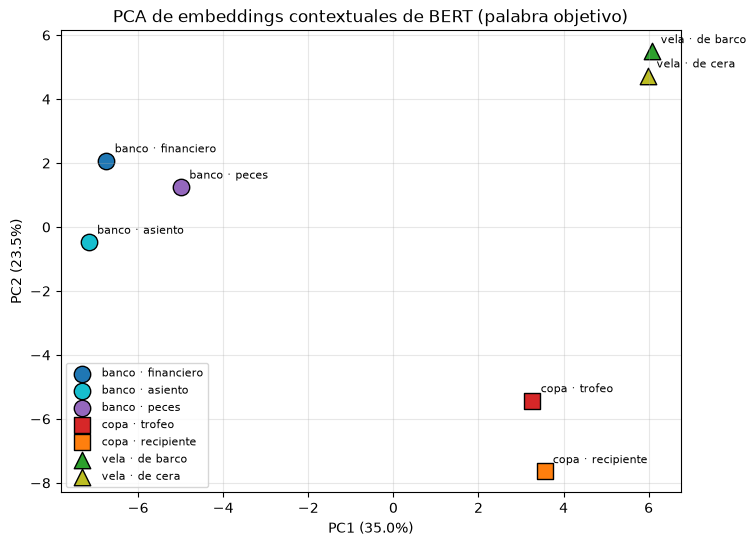

In [17]:
# ---------------- PCA a 2 dimensiones (manual, vía SVD) ----------------
X = torch.stack(bert_embs)                       # (7, 768)
Xc = X - X.mean(dim=0, keepdim=True)             # centrar
U, S, Vh = torch.linalg.svd(Xc, full_matrices=False)
Z = Xc @ Vh[:2].T                                # proyección en las 2 primeras componentes principales
var_ratio = (S ** 2) / (S ** 2).sum()
print("Varianza explicada PC1, PC2:", var_ratio[:2].numpy().round(3))

colors = {"banco · financiero": "tab:blue", "banco · asiento": "tab:cyan", "banco · peces": "tab:purple",
          "copa · trofeo": "tab:red", "copa · recipiente": "tab:orange",
          "vela · de barco": "tab:green", "vela · de cera": "tab:olive"}
markers = {"banco": "o", "copa": "s", "vela": "^"}

plt.figure(figsize=(8, 6))
for k, (sent, word, sense) in enumerate(examples):
    plt.scatter(Z[k, 0], Z[k, 1], c=colors[sense], marker=markers[word], s=140, label=sense, edgecolors="k")
    plt.annotate(sense, (Z[k, 0], Z[k, 1]), textcoords="offset points", xytext=(6, 6), fontsize=8)
plt.xlabel(f"PC1 ({var_ratio[0]*100:.1f}%)"); plt.ylabel(f"PC2 ({var_ratio[1]*100:.1f}%)")
plt.title("PCA de embeddings contextuales de BERT (palabra objetivo)")
plt.grid(alpha=0.3); plt.legend(fontsize=8, loc="best"); plt.show()